In [1]:
import torch
import pandas as pd
import torchvision
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
import os
from PIL import Image
from pathlib import Path
import config
import numpy as np
import copy
import os,csv,datetime
import time
from torch_lr_finder import LRFinder

#文件记录
os.makedirs("figs",exist_ok=True)
os.makedirs("results",exist_ok=True)
result_path = "results/folds.csv"
result_1_path="results/all.csv"

print(config.num_epochs)

/home/zhengxuyao/.conda/envs/menv/lib/python3.10/site-packages/torch_lr_finder/lr_finder.py:5: TqdmExperimentalWarning: Using `tqdm.autonotebook.tqdm` in notebook mode. Use `tqdm.tqdm` instead to force console mode (e.g. in jupyter console)
  from tqdm.autonotebook import tqdm


100


In [2]:
#时间戳
run_id = time.strftime("%Y%m%d_%H%M%S")

In [3]:
#随机种子
import random

def set_seed(seed=41):
    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # 尽可能保证 cuDNN 运算可复现
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

In [4]:
config_path = "results/config.csv"
need_header = not os.path.exists(config_path)

with open(config_path, "a", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    if need_header:
        writer.writerow([
            "time", "batch_size", "num_catogeries", "num_epochs",
            "learning_rate", "weight_decay", "n_splits",
        ])
    writer.writerow([
        datetime.datetime.now().isoformat(timespec="seconds"),
        config.batch_size,
        config.num_catogeries,
        config.num_epochs,
        config.learning_rate,
        config.weight_decay,
        config.n_splits,
    ])

In [5]:
#使用GPU
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [6]:
#数据预处理

#检查json结构
import json
train_path="./train/annotations_classification.json"

def inspect_json(path):
    with open(path,encoding="utf-8")as f:
        #加载数据
        data=json.load(f)

    print("顶层类型：", type(data).__name__) 

    if isinstance(data,dict):
        #key返回的只是一个对象，无法索引
        print("顶层key:{}".format(list(data.keys())))

        for k,v in data.items():
            if isinstance(v,list):
                print(f"{k},列表长度:{len(v)}")
                if v:
                    print(f"第一个元素类型: {type(v[0]).__name__}")
                    print(f"样例: {str(v[0])[:200]}")
            elif isinstance(v,dict):
                print(f"{k},{v}:dict,key:{list(v.keys())[:10]}")
    elif isinstance(data,list):
        print(f"列表长度:{len(data)}")
        if data:
            print(f"示例:{str(data[0])[:200]}")
            if isinstance(data[0],dict):
                print(f"{list(data[0].keys())[:10]}")

    return data

data=inspect_json(train_path)


顶层类型： dict
顶层key:['categories', 'images', 'image_labels']
categories,列表长度:10
第一个元素类型: dict
样例: {'id': 1, 'name': 'airplane'}
images,列表长度:585
第一个元素类型: dict
样例: {'id': 0, 'file_name': 'images/001.jpg', 'width': 958, 'height': 808}
image_labels,列表长度:585
第一个元素类型: dict
样例: {'image_id': 0, 'category_ids': [1]}


In [7]:
print(type(data))
'''
顶层是对象,且不等长数组,分开处理
'''

<class 'dict'>


'\n顶层是对象,且不等长数组,分开处理\n'

In [8]:
categories=pd.DataFrame(data["categories"])
train_images=pd.DataFrame(data["images"])
images_labels=pd.DataFrame(data["image_labels"])
#确定转换成功
print(type(categories),type(train_images))
#观察形状
print(categories.shape)
print(train_images.shape)
print(images_labels.shape)
#检测
print(categories.iloc[:,:])
print(train_images.iloc[:5,:])
print(images_labels.iloc[:5,:])

<class 'pandas.core.frame.DataFrame'> <class 'pandas.core.frame.DataFrame'>
(10, 2)
(585, 4)
(585, 2)
   id                name
0   1            airplane
1   2                ship
2   3        storage_tank
3   4    baseball_diamond
4   5        tennis_court
5   6    basketball_court
6   7  ground_track_field
7   8              harbor
8   9              bridge
9  10             vehicle
   id       file_name  width  height
0   0  images/001.jpg    958     808
1   1  images/002.jpg    950     806
2   2  images/003.jpg    889     803
3   3  images/004.jpg    946     732
4   4  images/005.jpg    966     753
   image_id category_ids
0         0          [1]
1         1          [1]
2         2          [1]
3         3          [1]
4         4          [1]


In [9]:
#数据处理
#删除id列
categories=categories.iloc[:,1:]    #这个应该只是用来最后的通过下标告诉这个到底是什么类别的
#合并,舍去，转为onehot
# train_images=pd.concat([train_images,images_labels],axis=0)

#对于标签转为独热编码
one_hot=[]
for label in images_labels["category_ids"].to_numpy():
    tmp=[0]*config.num_catogeries
    for idx in label:
        tmp[idx-1]=1
    one_hot.append(tmp)
train_images["one_hot"]=one_hot


In [10]:
#裁剪/缩放图片
min_width=min(train_images.to_numpy()[:,2])
min_height=min(train_images.to_numpy()[:,3])
print(min_width)    #533
print(min_height)   #358
#太小了，说明可能得检测整个分布，，不能一刀切破坏图片信息
max_width=max(train_images.to_numpy()[:,2])
max_height=max(train_images.to_numpy()[:,3])
print(max_width)    #1728
print(max_height)   #1028
#继续查看其他特征

# print(images.to_numpy().mean())
#检测缺失值
# num_na=0
# for x in images.to_numpy()[:,2]:
#     if not isinstance(x,int):
#         num_na=num_na+1
# print(num_na)   #无缺失值

print(train_images.to_numpy()[:,2].mean())    #937.8752136752137
print(train_images.to_numpy()[:,3].mean())    #609.2854700854701

num_900=0
for x in train_images.to_numpy()[:,2]:
    if x<600:
        num_900+=1
print(num_900)

533
358
1728
1028
937.8752136752137
609.2854700854701
4


In [11]:
class ResizeWithPad:
    def __init__(self, size=224, fill=0):
        self.size = size
        #填充的颜色
        self.fill = fill

    def __call__(self, img):
        w, h = img.size

        # 等比例缩放：让最长边变成 size
        scale = self.size / max(w, h)
        new_w = round(w * scale)
        new_h = round(h * scale)

        img = torchvision.transforms.Resize(
            (new_h, new_w),
            interpolation=torchvision.transforms.InterpolationMode.BILINEAR
        )(img)

        # 计算四周填充量
        pad_left = (self.size - new_w) // 2
        pad_top = (self.size - new_h) // 2
        pad_right = self.size - new_w - pad_left
        pad_bottom = self.size - new_h - pad_top

        img = torchvision.transforms.Pad(
            (pad_left, pad_top, pad_right, pad_bottom),
            fill=self.fill
        )(img)

        return img

In [12]:
#方向不对，不应该直接裁剪
#宽高比例
train_images["ratio"]=train_images["width"]/train_images["height"]
print(train_images["ratio"].describe())
print(train_images["ratio"].value_counts(bins=10).sort_index())

#ratio集中在其中的几个区域，说明数据集中，容易缩放
#随机裁剪+统一比例
train_tf=torchvision.transforms.Compose([
    #随机裁剪 + 缩放比例 + 不过这里其实也是一个超参数 : 0.7
    # torchvision.transforms.RandomResizedCrop(224,scale=(0.8,1.0)),
    #等比例缩放后中心裁剪
    torchvision.transforms.Resize(256),
    torchvision.transforms.CenterCrop(224),
    #直接拉伸
    # torchvision.transforms.Resize((224,224)),
    #缩放 + 填充
    # ResizeWithPad(224,0),
    #数据增强——正则化
    torchvision.transforms.RandomHorizontalFlip(),
    torchvision.transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    torchvision.transforms.ToTensor(),
    #归一化
    torchvision.transforms.Normalize([0.485, 0.456, 0.406],
                                    [0.229, 0.224, 0.225])
])

#验证时不能有随机的成分
# train_eval_tf=torchvision.transforms.Compose([

# ])

#不能随机裁剪,暂时用这个
test_tf=torchvision.transforms.Compose([
    torchvision.transforms.Resize(256),        # 短边缩到 256
    torchvision.transforms.CenterCrop(224),    # 中心裁 224
    torchvision.transforms.ToTensor(),
    #归一化
    torchvision.transforms.Normalize([0.485, 0.456, 0.406],
                                    [0.229, 0.224, 0.225])
])
#图片数据集
class MY_DATASET(Dataset):
    def __init__(self, df:pd.DataFrame , dir,tf):
        self.images_dir=dir
        self.df=df.reset_index(drop=True)   #不懂
        self.transform=tf

    def __len__(self):
        return len(self.df)

    def __getitem__(self,idx):
        #按整数取行
        row=self.df.iloc[idx]
        path=os.path.join(self.images_dir,row["file_name"])
        img=Image.open(path).convert("RGB")
        #实时转换
        img=self.transform(img)
        #独热编码,这里要转为tensor
        label = torch.tensor(row["one_hot"], dtype=torch.float32)

        return img,label

class MY_DATASET_NO_LABEL(Dataset):
    def __init__(self,dir,tf):
        self.img_dir=dir
        self.transform=tf
        # 枚举所有图片-----重点
        self.files = sorted([
            p.name for p in Path(self.img_dir).glob("*")
            if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
        ])

    def __len__(self):
        return len(self.files)

    def __getitem__(self,idx):
        name=self.files[idx]
        path=os.path.join(self.img_dir,self.files[idx])
        img=Image.open(path).convert("RGB")
        img=self.transform(img)

        return img,name

train_dataset=MY_DATASET(train_images,"./train",train_tf)
test_dataset=MY_DATASET_NO_LABEL("./test/images",test_tf)
print(test_dataset[0])
#dataloader
# def train_dataloader(train_dataset):
#     train_dataloader=DataLoader(
#         dataset=train_dataset,
#         batch_size=64,
#         shuffle=True,
#         num_workers=0,
#         drop_last=False
#     )
#     return train_dataloader



count    585.000000
mean       1.557593
std        0.235350
min        0.836066
25%        1.421687
50%        1.536028
75%        1.681750
max        2.823529
Name: ratio, dtype: float64
ratio
(0.833, 1.035]      5
(1.035, 1.234]     30
(1.234, 1.432]    118
(1.432, 1.631]    233
(1.631, 1.83]     146
(1.83, 2.029]      31
(2.029, 2.227]     15
(2.227, 2.426]      5
(2.426, 2.625]      1
(2.625, 2.824]      1
Name: count, dtype: int64
(tensor([[[-0.7137, -0.5938, -0.5082,  ...,  0.5022,  0.7762,  0.7933],
         [-0.6794, -0.6109, -0.6623,  ...,  0.8447,  0.8104,  0.7077],
         [-0.5596, -0.6794, -0.8335,  ...,  0.8618,  0.7419,  0.2453],
         ...,
         [-1.0219, -1.0048, -0.9705,  ..., -0.8507, -0.9192, -0.8849],
         [-1.0219, -1.0219, -0.9877,  ..., -0.9192, -0.9363, -0.8678],
         [-1.0219, -1.0219, -1.0048,  ..., -0.9534, -0.9363, -0.7650]],

        [[-0.5651, -0.4426, -0.3550,  ...,  0.8704,  1.1155,  1.0630],
         [-0.5301, -0.4601, -0.5126,  ...,  1.

完成了数据的处理和打包

In [13]:
from torchvision import models
from torch import nn

#迁移学习，使用预训练网络
# 加载预训练模型,使用第一版权重，更稳定
model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

# 改最后一层，输出改成 10 类
num_features = model.fc.in_features   # ResNet18 是 512
# model.fc = nn.Linear(num_features, 10)
model.fc = nn.Sequential(
    nn.Dropout(0.5),
    nn.Linear(num_features, 10)
)
model=model.to(device)

# 放到 GPU
# if torch.cuda.is_available():
#     model = model.to("cuda")

#多指标分类使用 BCE ，内置了 sigmoid,默认是mean
loss_fn=nn.BCEWithLogitsLoss().to(device)
# if torch.cuda.is_available():
#     loss_fn=loss_fn.cuda()

#评价指标
from torchmetrics.classification import MultilabelAveragePrecision

def macro_MAP(num_labels,preds,target):
    """
    preds是最终的logits,target是指标
    """
    metric = MultilabelAveragePrecision(num_labels=num_labels, average='macro').to(preds.device)
    preds = torch.sigmoid(preds)
    # 计算 Macro-mAP
    target = target.long().to(preds.device)
    map_score = metric(preds, target)

    return map_score.item()

In [14]:
def train(train_df,train_dir,train_tf,valid_df,valid_dir,valid_tf,
          model:nn.Module,loss,num_epochs,learning_rate,weight_decay):
    """返回每轮的loss和验证集上的metric指标已经训练好的网络"""
    #深拷贝网络
    net = copy.deepcopy(model)

    #评估时候对全部数据进行求loss
    train_ls  ,valid_ls=[],[]

    updater=torch.optim.Adam(
        net.parameters(),
        lr=learning_rate,
        weight_decay=weight_decay
    )
    #因为分批所以只能在此才建立数据集
    train_dataset=MY_DATASET(train_df,train_dir,train_tf)
    valid_dataset=MY_DATASET(valid_df,valid_dir,valid_tf)

    train_dataloader=DataLoader(train_dataset,batch_size=config.batch_size,shuffle=True,num_workers=4,drop_last=False,pin_memory=True)
    valid_loader = DataLoader(valid_dataset, batch_size=config.batch_size, shuffle=False, num_workers=4,pin_memory=True)

    #Early stop 参数
    patience=config.patience
    no_improve=0
    end_epoch=0
    best_map=-float("inf")

    for epoch in range(num_epochs):
        net.train()
        #小批量训练
        for data in train_dataloader:
            imgs,labels=data
            #数据搬到GPU
            imgs=imgs.to(device,non_blocking=True)
            labels=labels.to(device,non_blocking=True)

            logits=net(imgs)
            ls=loss(logits,labels)
            updater.zero_grad()
            ls.backward()
            updater.step()

        #评估
        net.eval()
        with torch.no_grad():
            #完整训练集每轮对于整个训练集的loss
            train_ls_sum=0
            for data in train_dataloader:
                imgs,labels=data
                imgs=imgs.to(device,non_blocking=True)
                labels=labels.to(device,non_blocking=True)

                train_logits=net(imgs)
                train_ls_sum+=loss(train_logits,labels).item()*imgs.shape[0]
            train_ls.append(train_ls_sum / len(train_dataset))

            #验证集的loss曲线和macro-MAP指标
            valid_ls_sum=0
            all_logits = []
            all_labels = []

            for data in valid_loader:
                imgs,labels=data
                imgs=imgs.to(device,non_blocking=True)
                labels=labels.to(device,non_blocking=True)
                
                valid_logits=net(imgs)
                valid_ls_sum+=loss(valid_logits,labels).item()*imgs.shape[0]
                all_logits.append(valid_logits)
                all_labels.append(labels)
            valid_ls.append(valid_ls_sum / len(valid_dataset))
            #评估指标
            all_logits = torch.cat(all_logits, dim=0)
            all_labels = torch.cat(all_labels, dim=0)
            metric=macro_MAP(config.num_catogeries,all_logits,all_labels)

            #Early stop
            #未收敛
            if metric > best_map + 1e-4:
                no_improve=0
                best_map=metric
                end_epoch=epoch
                best_state = copy.deepcopy(net.state_dict())
            else:
                no_improve+=1
                if no_improve >= patience:
                    print(f"Early stop at epoch {epoch}, best mAP={best_map:.4f}")
                    break

    #换成最佳权重
    net.load_state_dict(best_state)

    return train_ls,valid_ls,net,best_map,end_epoch


  0%|          | 0/100 [00:00<?, ?it/s]

Learning rate search finished. See the graph with {finder_name}.plot()
LR suggestion: steepest gradient
Suggested LR: 1.07E-03


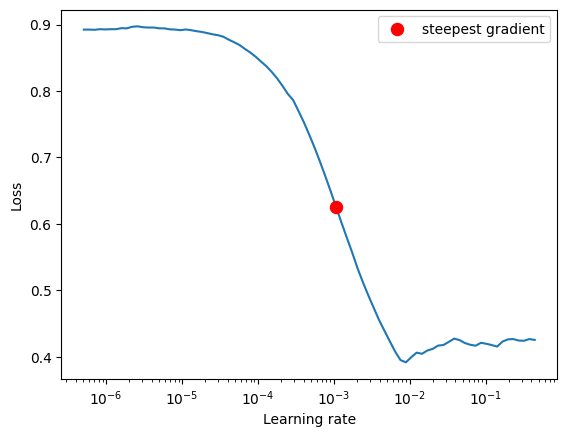


全局最大差异: 0
✅ reset 生效，权重已恢复


In [15]:
#学习率测试器
before_state = copy.deepcopy(model.state_dict())

train_dataloader=DataLoader(train_dataset,batch_size=config.batch_size,shuffle=True,num_workers=4,drop_last=False,pin_memory=True)

optimizer=torch.optim.Adam(
        model.parameters(),
        lr=1e-7,
        weight_decay=config.weight_decay
    )

lr_finder=LRFinder(model,optimizer,loss_fn,device="cuda")
#取100个batch来跑
lr_finder.range_test(train_dataloader,end_lr=1,num_iter=100)
lr_finder.plot()
lr_finder.reset()


# LR Finder 之后
after_state = model.state_dict()

# 比较每一层权重的最大差异
max_diff = 0
for k in before_state:
    diff = (before_state[k] - after_state[k]).abs().max().item()
    max_diff = max(max_diff, diff)
    if diff > 1e-6:
        print(f"{k}: max diff = {diff}")

print(f"\n全局最大差异: {max_diff}")
if max_diff < 1e-6:
    print("✅ reset 生效，权重已恢复")
else:
    print("❌ reset 没生效，权重被改变了")

Early stop at epoch 13, best mAP=0.9297
折1,训练第一次loss:0.206598, 验证第一次loss:0.252003
折1,训练后loss:0.067888, 验证后loss:0.146477
Early stop at epoch 20, best mAP=0.9336
折2,训练第一次loss:0.243143, 验证第一次loss:0.282445
折2,训练后loss:0.102441, 验证后loss:0.150356
Early stop at epoch 13, best mAP=0.9099
折3,训练第一次loss:0.250259, 验证第一次loss:0.259414
折3,训练后loss:0.052220, 验证后loss:0.124527
Early stop at epoch 13, best mAP=0.8989
折4,训练第一次loss:0.260725, 验证第一次loss:0.282152
折4,训练后loss:0.114372, 验证后loss:0.182486
Early stop at epoch 13, best mAP=0.8889
折5,训练第一次loss:0.233265, 验证第一次loss:0.266327
折5,训练后loss:0.063063, 验证后loss:0.191265
5-折验证: 平均训练loss: 0.079997, 平均验证loss: 0.159022
第1折模型的macro-MAP评估分数: 0.929726779460907
第2折模型的macro-MAP评估分数: 0.9336370825767517
第3折模型的macro-MAP评估分数: 0.9099187254905701
第4折模型的macro-MAP评估分数: 0.8989459872245789
第5折模型的macro-MAP评估分数: 0.8889350891113281


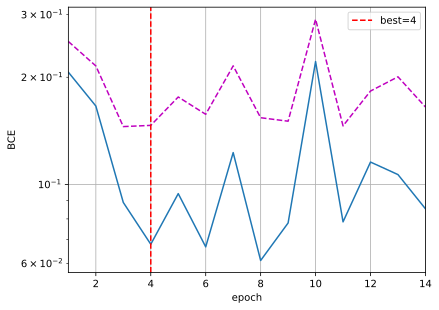

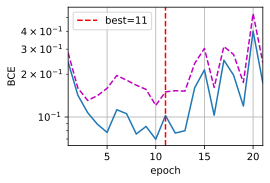

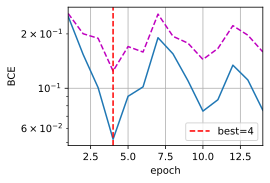

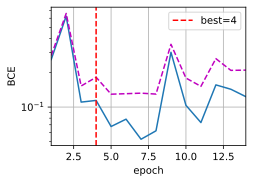

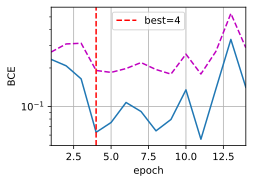

In [16]:
#k折实验
# from sklearn.model_selection import StratifiedKFold
#多指标分类器
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold
from d2l import torch as d2l

#拆分
# skf = StratifiedKFold(config.n_splits, shuffle=True, random_state=42)
mskf = MultilabelStratifiedKFold(config.n_splits, shuffle=True, random_state=42)

train_l_sum , valid_l_sum =0,0
fold_model=[]
fold_score=[]

header = ["time", "fold", "train_loss", "valid_loss", "macro_map"]
# need_header = not os.path.exists(result_path)
#拆分成分布类似的集合
for fold,(train_idx, valid_idx) in enumerate(mskf.split(train_images, np.array(train_images["one_hot"].tolist()))):
    train_df=train_images.iloc[train_idx].reset_index(drop=True)
    valid_df=train_images.iloc[valid_idx].reset_index(drop=True)

    #每一折前都要重新取模型

    train_dir="./train"
    train_ls , valid_ls , net_trained , metric ,end_epoch= train(train_df,train_dir,train_tf,
                                                        valid_df,train_dir,test_tf,
                                                        model,loss_fn,config.num_epochs,
                                                        config.learning_rate,config.weight_decay)
    #截取每个模型的最后一轮的loss
    train_l_sum+=train_ls[end_epoch]
    valid_l_sum+=valid_ls[end_epoch]
    #每一折后都作图
    epochs_ran=len(train_ls)
    d2l.plt.figure()
    d2l.plt.title(f"Fold {fold + 1}") 
    # d2l.plot(list(range(1, end_epoch + 2)), [train_ls[:end_epoch + 1 ], valid_ls[:end_epoch + 1 ]],
    #             xlabel='epoch', ylabel='BCE', xlim=[1, end_epoch + 1],
    #             legend=['train', 'valid'], yscale='log')
    d2l.plot(list(range(1, epochs_ran + 1)), [train_ls, valid_ls],
         xlabel='epoch', ylabel='BCE', xlim=[1, epochs_ran],
         legend=['train', 'valid'], yscale='log')
    d2l.plt.axvline(end_epoch + 1, color='red', linestyle='--', label=f'best={end_epoch+1}')
    d2l.plt.legend()
    
    #记录到文件中
    d2l.plt.savefig(f"figs/fold_{fold + 1}_loss_{run_id}.png", dpi=200, bbox_inches='tight')

    if not os.path.exists(result_path) or os.path.getsize(result_path) == 0:
        with open(result_path, "w", newline="", encoding="utf-8") as f:
            csv.writer(f).writerow(header)

    with open(result_path, "a", newline="", encoding="utf-8") as f:
        writer = csv.writer(f)
        writer.writerow([
            datetime.datetime.now().isoformat(timespec="seconds"),
            fold + 1,
            train_ls[end_epoch],
            valid_ls[end_epoch],
            metric,
        ])

    print(f'折{fold + 1},训练第一次loss:{float(train_ls[0]):f}, '
              f'验证第一次loss:{float(valid_ls[0]):f}')

    print(f'折{fold + 1},训练后loss:{float(train_ls[end_epoch]):f}, '
              f'验证后loss:{float(valid_ls[end_epoch]):f}')
    #模型评估记录
    # fold_model.append(net_trained)
    fold_model.append({k: v.cpu() for k, v in net_trained.state_dict().items()})
    fold_score.append(metric)

    # #一折实验处理
    # break

print(f'{config.n_splits}-折验证: 平均训练loss: {float(train_l_sum / config.n_splits):f}, '
      f'平均验证loss: {float(valid_l_sum / config.n_splits):f}')
for fold in range(config.n_splits):
    print(f"第{fold + 1}折模型的macro-MAP评估分数: {fold_score[fold]}")
    # #一折实验处理
    # break


In [17]:
# #不进行k折实验

# def train_and_preds(train_df,train_dir,train_tf,valid_df,valid_dir,valid_tf,
#           model:nn.Module,loss,num_epochs,learning_rate,weight_decay):
#     """测试函数,对训练集和测试集全部测试,且训练集用macro-MAP进行评估模型"""
#     header_1 = ["time", "train_loss", "valid_loss", "macro_map"]
#     # need_header_1 = not os.path.exists(result_1_path)
#     #训练集直接训练
#     train_ls , valid_ls , net_trained , metric ,end_epoch= train(train_df,train_dir,train_tf,
#                                                        valid_df,valid_dir,valid_tf,
#                                                        model,loss,num_epochs,
#                                                        learning_rate,weight_decay)

#     d2l.plt.figure()
#     epochs_ran=len(train_ls)
#     d2l.plot(list(range(1, epochs_ran + 1)), [train_ls, valid_ls],
#          xlabel='epoch', ylabel='BCE', xlim=[1, epochs_ran],
#          legend=['train', 'valid'], yscale='log')
#     d2l.plt.axvline(end_epoch + 1, color='red', linestyle='--', label=f'best={end_epoch+1}')
#     d2l.plt.legend()

#     # d2l.plot(list(range(1, end_epoch + 2)), [train_ls[:end_epoch + 1 ], valid_ls[:end_epoch + 1 ]],
#     #             xlabel='epoch', ylabel='BCE', xlim=[1, end_epoch + 1],
#     #             legend=['train', 'valid'], yscale='log')

#     if not os.path.exists(result_1_path) or os.path.getsize(result_1_path) == 0:
#       with open(result_1_path, "w", newline="", encoding="utf-8") as f:
#           csv.writer(f).writerow(header_1)
#     #记录数据
#     with open(result_1_path, "a", newline="", encoding="utf-8") as f:
#         writer = csv.writer(f)
#         writer.writerow([
#             datetime.datetime.now().isoformat(timespec="seconds"),
#             train_ls[end_epoch],
#             valid_ls[end_epoch],
#             metric,
#         ])

#     print(f'训练第一次loss:{float(train_ls[0]):f}, '
#           f'验证第一次loss:{float(valid_ls[0]):f}')

#     print(f'训练后loss:{float(train_ls[end_epoch]):f}, '
#           f'验证后loss:{float(valid_ls[end_epoch]):f}')
    
#     print(f"macro-MAP评估分数: {metric}")
    
#     #测试集测试,并组装 json
#     net_trained.eval()
#     with torch.no_grad():     #这些细节还是得加强理解
#       all_outputs = []
#       test_dataloader=DataLoader(test_dataset,config.batch_size,shuffle=False,num_workers=0,pin_memory=True)  #这里有几个参数不懂
#       for imgs,name in test_dataloader:
#         imgs=imgs.to(device,non_blocking=True)
#         # name=name.to(device,non_blocking=True)
        
#         #加了sigmoid处理
#         test_output=torch.sigmoid(net_trained(imgs))
#         all_outputs.append(test_output)
#       all_outputs=torch.cat(all_outputs,dim=0).cpu().numpy()
      
#       #组装json
#       ans=[]
#       for i, image_name in enumerate(test_dataset.files):
#         image_id = int(image_name.split('.')[0])
#         score = all_outputs[i].tolist()
#         ans.append({"image_id": image_id, "score": score})
#          #其参数是中文正常显示，有合理的缩进，将python对象转为json字符串
#       # json_str = json.dumps(ans, ensure_ascii=False, indent=2)
#       with open("classification_predictions.json", "w", encoding="utf-8") as f:
#         json.dump(ans, f, ensure_ascii=False, indent=2)

# #要注意循环变量的遗传，所以最好都写成函数
# train_and_preds(train_images,train_dir,train_tf,train_images,train_dir,test_tf,model,loss_fn,config.num_epochs,
#                 config.learning_rate,config.weight_decay)

In [18]:
def ensemble_predict(fold_models, model_template, test_loader, device):
    """
    fold_models: list of state_dict
    model_template: 未训练的模型结构（用来加载权重）
    test_loader: 测试集 DataLoader
    返回: (N, 10) 的平均概率
    """
    all_fold_probs = []

    for fold_idx, state_dict in enumerate(fold_models):
        # 1. 加载这一折的权重
        model = copy.deepcopy(model_template)
        model.load_state_dict(state_dict)
        model = model.to(device)
        model.eval()

        # 2. 预测测试集
        fold_probs = []
        with torch.no_grad():
            for imgs, _ in test_loader:
                imgs = imgs.to(device, non_blocking=True)
                logits = model(imgs)
                probs = torch.sigmoid(logits)
                fold_probs.append(probs.cpu())

        fold_probs = torch.cat(fold_probs, dim=0)   # (N, 10)
        all_fold_probs.append(fold_probs)
        print(f"Fold {fold_idx+1} 预测完成，形状: {fold_probs.shape}")

    # 3. 取平均
    all_fold_probs = torch.stack(all_fold_probs, dim=0)   # (K, N, 10)
    final_probs = all_fold_probs.mean(dim=0)              # (N, 10)

    return final_probs.numpy()


In [24]:
test_dataset = MY_DATASET_NO_LABEL("./test/images", test_tf)
test_loader = DataLoader(test_dataset, batch_size=config.batch_size,
                         shuffle=False, num_workers=0, pin_memory=True)

# 用集成预测
final_probs = ensemble_predict(fold_model, model, test_loader, device)

# 组装 json
ans = []
for i, image_name in enumerate(test_dataset.files):
    image_id = int(image_name.split('.')[0])
    scores = final_probs[i]
    ans.append({"image_id": image_id, "scores": scores})

# 手动构建 JSON 字符串
def dumps_with_3_decimals(data, indent=2):
    lines = ["["]
    for idx, item in enumerate(data):
        scores_str = ", ".join(f"{x:.3f}" for x in item["scores"])
        line = f'  {{"image_id": {item["image_id"]}, "scores": [{scores_str}]}}'
        if idx < len(data) - 1:
            line += ","
        lines.append(line)
    lines.append("]")
    return "\n".join(lines)

json_str = dumps_with_3_decimals(ans)

with open("2025352016_郑旭尧_classification_predictions.json", "w", encoding="utf-8") as f:
    f.write(json_str)

Fold 1 预测完成，形状: torch.Size([65, 10])
Fold 2 预测完成，形状: torch.Size([65, 10])
Fold 3 预测完成，形状: torch.Size([65, 10])
Fold 4 预测完成，形状: torch.Size([65, 10])
Fold 5 预测完成，形状: torch.Size([65, 10])
